# Figure 4: chromatin state clusters
Clusters hotspot loci on their 2 kb accessibility profiles in WT, Dnmt-TKO and Tet-TKO rostral neural plate (ectoderm) cells, and writes the browser tracks for Fig. 4f and 5d.
Cheng, Stok Ranen et al., bioRxiv, doi:10.64898/2026.05.14.725081.

- **4a**: HCG TSS accessibility clusters (section: Accessibility heatmaps)
- **4b, 4c**: HCG TSS cluster accessibility and methylation profiles (section: Cluster profiles)
- **4d, 4e**: ICG haCREs (d) and laCREs (e) (sections: Accessibility heatmaps, Cluster profiles)
- **4f**: browser tracks at ICG laCREs; wig files only, the panel is a UCSC screenshot (section: Genome browser tracks)
- **ED7a-d**: Tet1 catalytic mutant; images, no code
- **ED7e**: CTCF site accessibility clusters (section: Accessibility heatmaps)
- **ED7f, ED7g**: CTCF cluster accessibility and methylation profiles (section: Cluster profiles)
- **ED7h**: LCG and ICG TSS clusters (sections: LCG and ICG TSS clusters, Cluster profiles)

Figures go to `figs/Spatials/` (through `out_path`, so under `git_test/`). The stored notebook has no outputs.

## Initialization

In [1]:
source("paths.R")
save_figure = F  # TRUE also writes every figure to git_test/ (see show_fig() in paths.R)

In [2]:
library(tgstat)
library(tidyr)
library(ggplot2)
library(tibble)
library(prego)
library(misha)
library(misha.ext)
library(ggpubr)
library(tidyverse)
library(tgutil)

options(scipen = 999)

In [3]:
source(file.path(repo_dir, "scripts/ATAC_preprocessing.r"))
source(file.path(repo_dir, "scripts/ATAC_spatial.r"))

- `rerun_init = F`: read the ATAC model `mod` from `data/output/mod.RDS` instead of rebuilding it with `init()` (`scripts/ATAC_preprocessing.r`).
- `rerun_classification_and_clustering = T`: re-run the clustering instead of reading `data/output/spat_mats.RDS` and `spat_kms.RDS`.
- The cell after the flags reads `mod.RDS` again; it is redundant.

In [4]:
rerun_init = F
rerun_classification_and_clustering = T

In [5]:
if (rerun_init){
    message("Rerunning mod initialization.")
    mod = init()
    saveRDS(mod, out_path("./data/output/mod.RDS"))
} else {
    message("Reading existing mod.")
    mod = readRDS(in_path("./data/output/mod.RDS"))
}

In [6]:
mod = readRDS(in_path("./data/output/mod.RDS"))

## Spatial clustering of hotspot loci
Hotspot classes (`mod$ehs$mode`, from `build_epi_hotspots_classes` in `scripts/ATAC_preprocessing.r`):
- `tss_hcg`: TSSs without CTCF in a CpG-rich interval (500 bp CpG density > 0.022) with max CpG density > 0.04 (Fig. 4a-c)
- `tss_icg`: as `tss_hcg`, max CpG density < 0.04 (ED7h)
- `tss_lcg`: TSSs outside such intervals (ED7h)
- `ins_sctcf`: CTCF peaks with ChIP score >= 50, >= 1 kb from a TSS, centred and oriented on the CTCF peak (ED7e-g)
- `icg_senh` / `icg_wenh`: non-TSS peaks in a CpG interval with max CpG density < 0.04; mean WT log2 accessibility (rostral neural plate and ExE mesoderm progenitors) >= -16.5 (haCRE, 4d) or < -16.5 (laCRE, 4e)

Clustering (`cluster_ehs_spat_mats`, `scripts/ATAC_spatial.r`):
- ATAC counts in 20 bp bins over ±1 kb (101 bins) in rostral neural plate (`rnp`) cells: WT (WT embryos + chimera hosts), Dnmt-TKO, Tet-TKO.
- Mutants corrected for aneuploid chromosomes; all genotypes downsampled to matched coverage.
- Profiles concatenated (Dnmt-TKO, WT, Tet-TKO); TGL k-means on log2(0.25 + count), k = max(4, min(32, n/200)), seed 28.
- Rows ordered by hierarchical clustering within a cluster, smoothed with a 20-locus running mean.
- `tss_icg` and `tss_lcg` use `filter_low_signal = T` (drops loci with < 10 reads).
- Writes `data/output/spat_mats/mat_<mode>.RDS`, `data/output/spat_mats.RDS`, `data/output/spat_kms.RDS`.

In [7]:
these_states = c("rnp")

if (rerun_classification_and_clustering){
    mode_cnt = table(mod$ehs$mode)
    a = cluster_ehs_spat_mats(mod, modes = c("tss_hcg", "ins_sctcf", "icg_senh", "icg_wenh"), states = these_states, km_seed = 28)
    a_supp = cluster_ehs_spat_mats(mod, modes = c("tss_icg", "tss_lcg"), states = these_states, km_seed = 28, filter_low_signal = T)
    
    a$all_mats$rnp = c(a$all_mats$rnp, a_supp$all_mats$rnp)
    a$all_kms$rnp = c(a$all_kms$rnp, a_supp$all_kms$rnp)
    
    for(nm in names(a$all_mats$rnp)) {
        message("Writing ", nm, "...")
        saveRDS(a$all_mats$rnp[[nm]], file=out_path(sprintf("data/output/spat_mats/mat_%s.RDS", nm)))
    }

    spat_mats = a$all_mats
    spat_kms = a$all_kms

    for (st in these_states){
        for (i in 1:length(spat_mats[[st]])){
            mat = spat_mats[[st]][[i]]
            rownames(mat) = gsub(" ", "", rownames(mat))
            spat_mats[[st]][[i]] = mat
        }
    }
    
    saveRDS(spat_mats, out_path("data/output/spat_mats.RDS"))
    saveRDS(spat_kms, out_path("data/output/spat_kms.RDS"))

} else {
    spat_mats = readRDS(file=in_path("data/output/spat_mats.RDS"))
    spat_kms = readRDS(file=in_path("data/output/spat_kms.RDS"))
}

## Accessibility heatmaps (Fig. 4a, d, e; ED7e)
- **4a**: HCG TSS accessibility clusters
- **4d, 4e**: ICG haCREs and laCREs
- **ED7e**: CTCF site clusters

`plot_spat_kms_named` (a copy of `plot_spat_kms` that also stores locus order and cluster names) draws log2(0.25 + x), clipped to [-2, 4], with Dnmt-TKO, WT and Tet-TKO side by side.
- Clusters are ranked by their maximum in the most accessible genotype block; C1 is the most accessible (top).
- The C1, C2, ... names are kept in `mode_md` and reused by the profile plots.
- It reads `spat_mats`, `spat_kms` and `mode_md` from the global environment.

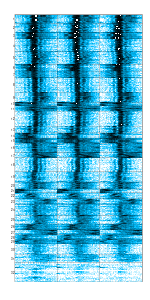

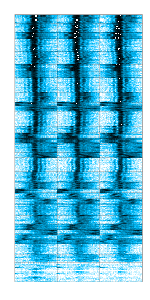

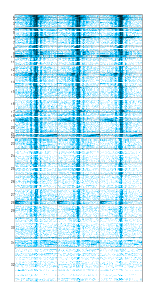

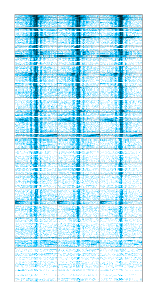

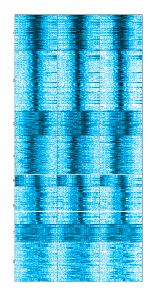

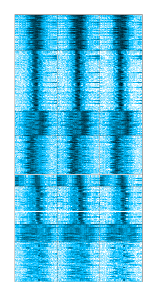

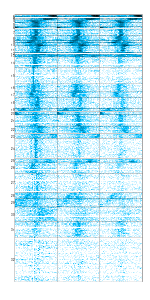

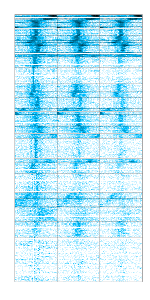

In [8]:
source(file.path(repo_dir, "scripts/ATAC_spatial.r"))

mode_md = list()

for (this_mode in c("tss_hcg", "ins_sctcf", "icg_senh", "icg_wenh")){
    mode_md = plot_spat_kms_named(this_mode, "rnp", spat_mats, spat_kms, mode_md, "figs/Spatials/spats/")
}

Writes `figs/Spatials/spats/<mode>.rnp_num.png` and `<mode>.rnp_nonnum.png` (with and without cluster numbers):
- `tss_hcg`: **4a**
- `icg_senh`: **4d**
- `icg_wenh`: **4e**
- `ins_sctcf`: **ED7e**


## LCG and ICG TSS clusters (ED7h)
- **ED7h**: LCG and ICG TSS clusters, with profiles of representative clusters

Same heatmaps for `tss_icg` and `tss_lcg` with `plot_spat_kms`, clusters ordered by position along the window (`order_by = "weighted_average"`).
Writes `figs/Spatials/spats/tss_icg.rnp_{num,nonnum}.png` and `tss_lcg.rnp_{num,nonnum}.png`. Profiles are in section "Cluster profiles".

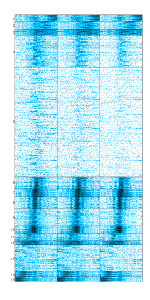

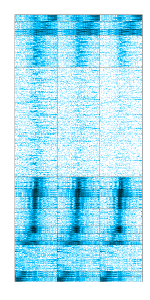

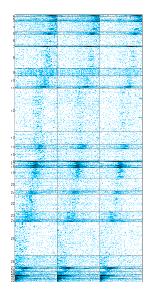

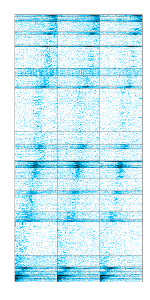

In [9]:
source(file.path(repo_dir, "scripts/ATAC_spatial.r"))
for (this_mode in c("tss_icg", "tss_lcg")){
    mode_md = plot_spat_kms(this_mode, "rnp", spat_mats, spat_kms, mode_md, "figs/Spatials/spats/", order_by = "weighted_average")
}

Writes the shared heatmap colour scale to `figs/Spatials/Fig4_scale.pdf`.

In [10]:
shades = colorRampPalette(c("white", "deepskyblue", "deepskyblue4", "black"))(1000)
marg = c(2,1,2,15)

vec <- seq(-2,4,l=999)
points <- seq(from = 1, to = length(vec), length.out = 7)
selected_points <- vec[round(points)]
show_fig("./figs/Spatials/Fig4_scale.pdf", show = FALSE, width = 7, height = 20, draw = {
    par(mar = marg)
    image(1, 1:100, t(as.matrix(1:100)), col = shades, axes = FALSE, xlab = "", ylab = "")
    axis(4, at = seq(1, 100, length.out = 7), labels = round(selected_points, 2), las = 1, cex.axis = 5)
})

## Cluster profiles (Fig. 4b-e; ED7f-h)
- **4b**: HCG TSS cluster accessibility, three genotypes
- **4c**: HCG TSS cluster methylation, WT and three Tet mutant lines
- **ED7f**: CTCF cluster accessibility
- **ED7g**: CTCF cluster methylation

- `plot_acc_trend`: k-means centre per cluster; Dnmt-TKO (blue) vs WT (black dashed), and Tet-TKO (red) vs WT.
- `plot_meth_trend`: mean EM-seq methylation per cluster in 20 bp bins, smoothed over 20 bins.
  - Left: WT vs Tet-TKO chimera cells (`CHIM.comb_wt_E8_5`, `CHIM.comb_tet_tko_E8_5`).
  - Right: WT (`embdnmt.HTNC`) vs Tet23-DKO (`embdnmt.DKO23S1`) and Tet23-DKO; Tet1-CD (`embdnmt.Tet1CDS1`).
  - Blue dashed line at 0: expected Dnmt-TKO methylation.
- Both need `mode_md`, so run the heatmap sections first.

In [11]:
source(file.path(repo_dir, "scripts/ATAC_spatial.r"))
for (this_mode in c("tss_hcg", "ins_sctcf", "icg_senh", "tss_icg", "tss_lcg", "icg_wenh")){
    plot_acc_trend(st = "rnp", this_mode, "png")
    plot_meth_trend(st = "rnp", this_mode, "png")
}

Writes `figs/Spatials/acc_trends/<mode>/C<k>.png` and `figs/Spatials/meth_trends/<mode>/C<k>.png`:
- `tss_hcg`: **4b**, **4c**
- `icg_senh`, `icg_wenh`: profiles of **4d**, **4e**
- `ins_sctcf`: **ED7f**, **ED7g**
- The paper shows representative clusters only.

**ED7h** profiles (`tss_icg`, `tss_lcg`) as PDF: `figs/Spatials/acc_trends/<mode>/C<k>.pdf` and `figs/Spatials/meth_trends/<mode>/C<k>.pdf`.

In [12]:
source(file.path(repo_dir, "scripts/ATAC_spatial.r"))
for (this_mode in c("tss_icg", "tss_lcg")){
    plot_acc_trend(st = "rnp", this_mode, "pdf")
    plot_meth_trend(st = "rnp", this_mode, "pdf")
}

Saves `data/output/spat_mats.RDS`, `spat_kms.RDS` and `cluster_renaming.RDS`.

In [13]:
saveRDS(spat_mats, file=out_path("data/output/spat_mats.RDS"))
saveRDS(spat_kms, file=out_path("data/output/spat_kms.RDS"))

In [14]:
cluster_renaming = lapply(mode_md, function(x) x[[1]])
saveRDS(cluster_renaming, file=out_path("data/output/cluster_renaming.RDS"))                          

## Genome browser tracks (Fig. 4f, 5d)
- **4f**: accessibility tracks at ICG laCREs, with WT and Tet-TKO methylation
- **5d**: ectoderm accessibility tracks at TSSs from 5c

Builds summed per-lineage misha tracks and writes UCSC wig files; the panels are UCSC screenshots.
- Tracks summed in 280 bp windows at 20 bp steps (`write_gb_wigs`), scaled to the smallest library in a set (`scale_to_min`).
- Writes `ucsc_tracks/<track>.wig` (through `out_path`); convert with the printed `wigToBigWig` commands.
- Original files: `embdnmt/ucsc_tracks/` and a bedGraph hub of the rnp tracks in `embdnmt/hub_p2p_rnp/`.
- `recreate_gb_tracks = FALSE` keeps the existing `GBmeso` and `GBexemeso` misha tracks; `TRUE` rebuilds them.
- Methylation wigs: E8.5 chimera tracks (`CHIM.comb_wt_E8_5`, `CHIM.comb_tet_tko_E8_5`).

In [15]:
library(misha)
library(misha.ext) # fwrite_ucsc, gextract_meth
library(dplyr)
gsetroot(mm10_trackdb)
options(gmax.data.size = 1e+9)

recreate_gb_tracks = FALSE # TRUE re-creates the summed GBmeso / GBexemeso tracks in the misha database
ucsc_dir = out_path("./ucsc_tracks")
dir.create(ucsc_dir, showWarnings = FALSE, recursive = TRUE)

track_colors = list(
    DNMT_TKO  = "#003366",
    DNMT_host = "#C8C8C8",
    TET_TKO   = "#8B0000",
    TET_host  = "#505050"
)
genos = c("DNMT_TKO_KO", "DNMT_TKO_host", "TET_TKO_KO", "TET_TKO_host")

### Mesoderm (GBmeso): pmeso + cardiac mesoderm + lnm

In [16]:
scale_factors_pmeso <- scale_to_min(paste0("mut_multi2.", genos, ".pmeso"))
scale_factors_card_meso <- scale_to_min(paste0("mut_multi2.", genos, ".card_meso"))
scale_factors_lnm <- scale_to_min(paste0("mut_multi2.", genos, ".lnm"))

if (recreate_gb_tracks){
    for (g in genos){
        gtrack.create(
            track = sprintf("mut_multi2.%s.GBmeso", g),
            description = sprintf("Summed tracks for %s mesoderm.", g),
            expr = sprintf('psum(
                      (mut_multi2.%s.pmeso     * scale_factors_pmeso[["mut_multi2.%s.pmeso"]]),
                      (mut_multi2.%s.card_meso * scale_factors_card_meso[["mut_multi2.%s.card_meso"]]),
                      (mut_multi2.%s.lnm       * scale_factors_lnm[["mut_multi2.%s.lnm"]]),
                      na.rm = TRUE)', g, g, g, g, g, g),
            iterator = 20
        )
    }
    gdb.reload()
}

write_gb_wigs(paste0("mut_multi2.", genos, ".GBmeso"))

### ExE mesoderm (GBexemeso): ac + ac_prog

In [17]:
scale_factors_ac <- scale_to_min(paste0("mut_multi2.", genos, ".ac"))
scale_factors_ac_prog <- scale_to_min(paste0("mut_multi2.", genos, ".ac_prog"))

if (recreate_gb_tracks){
    for (g in genos){
        gtrack.create(
            track = sprintf("mut_multi2.%s.GBexemeso", g),
            description = sprintf("Summed tracks for %s ExE mesoderm.", g),
            expr = sprintf('psum((mut_multi2.%s.ac * scale_factors_ac[["mut_multi2.%s.ac"]]),
                      (mut_multi2.%s.ac_prog * scale_factors_ac_prog[["mut_multi2.%s.ac_prog"]]), na.rm = TRUE)', g, g, g, g),
            iterator = 20
        )
    }
    gdb.reload()
}

write_gb_wigs(paste0("mut_multi2.", genos, ".GBexemeso"))

### Rostral neural plate (rnp)
Per-genotype rnp tracks, the ectoderm tracks of Fig. 5d.
- The rnp wigs in `ucsc_tracks/` predate this cell (it was disabled in the original notebook and used the ExE mesoderm scale factors).

In [18]:
rnp_tracks = paste0("mut_multi2.", genos, ".rnp")
write_gb_wigs(rnp_tracks, scale = scale_to_min(rnp_tracks))

### Methylation: WT and Tet-TKO E8.5 (CHIM tracks)

In [19]:
span = 20
data_m <- gextract_meth(
  tracks = c("CHIM.comb_wt_E8_5", "CHIM.comb_tet_tko_E8_5"),
  names = c("WT_m", "TET_TKO_m"),
  intervals = gintervals.all(),
  extract_meth_calls = TRUE,
  d_expand = 200
)
data_m = data_m %>% left_join(gintervals.all() %>% dplyr::rename(chrstart=start, chrend=end), by="chrom") %>% filter(end+span <= chrend)

fwrite_ucsc(data_m %>% select(chrom, start, end, WT_m) %>% dplyr::rename(score = WT_m), file = file.path(ucsc_dir, "WT_meth.wig"), name = "WT_meth", description = "WT_meth", type="wig", span = span, color = "grey20")
fwrite_ucsc(data_m %>% select(chrom, start, end, TET_TKO_m) %>% dplyr::rename(score = TET_TKO_m), file = file.path(ucsc_dir, "TET_TKO_meth.wig"), name = "TET_TKO_meth", description = "TET_TKO_meth", type="wig", span = span, color = "brown2")

for (tr in c("WT_meth", "TET_TKO_meth")){
    cat(sprintf("wigToBigWig %s/%s.wig %s %s/%s.bw\n", ucsc_dir, tr, mm10_chrom_sizes, ucsc_dir, tr))
}